Dataset already exists locally.
Rows: 11084 | Date range: 1980-12-12 → 2024-11-29

TEST ACCURACY: 0.43806509945750455

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        SELL       0.28      0.22      0.25       467
         BUY       0.39      0.06      0.11       754
        HOLD       0.48      0.83      0.60       991

    accuracy                           0.44      2212
   macro avg       0.38      0.37      0.32      2212
weighted avg       0.41      0.44      0.36      2212


================ CURRENT MARKET SIGNAL ================
Signal: HOLD
Confidence: 99.17%


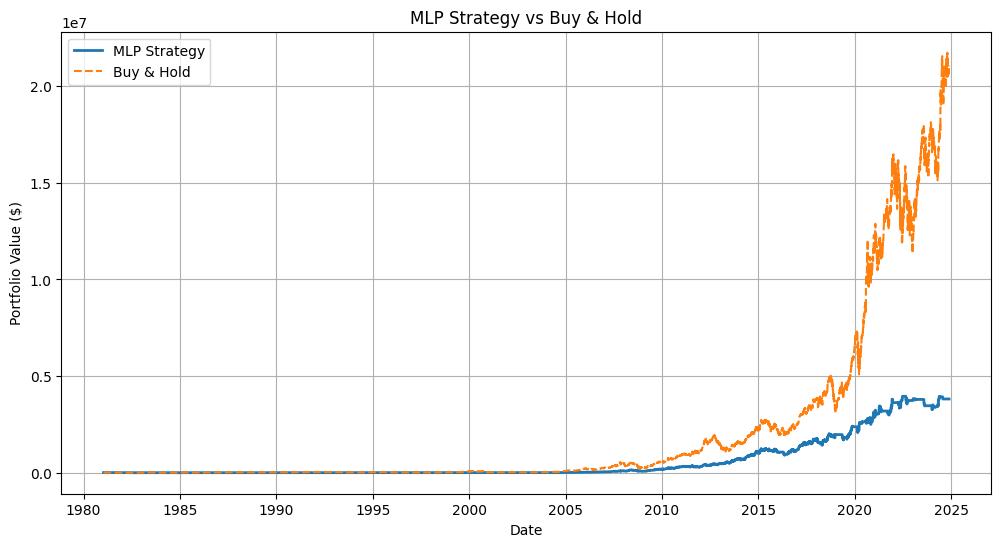


PROJECT EXECUTED SUCCESSFULLY ✔


In [7]:
# ============================================================
# Buy / Sell Recommendation System using MLP
# REAL MARKET DATA FROM CSV (GITHUB LINK)
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from urllib.request import urlretrieve

from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ============================================================
# 1. Download REAL Market Data CSV (if not exists)
# ============================================================

DATA_URL = "https://github.com/FarhanAli97/Apple-AAPL-Stock-Data-1980-to-December-2024/raw/main/Apple%20(AAPL)%20From%201980%20To%20Dec-2024.csv"
DATA_CSV = "AAPL.csv"

if not os.path.exists(DATA_CSV):
    print("Downloading AAPL.csv from GitHub...")
    urlretrieve(DATA_URL, DATA_CSV)
    print("Download complete!")
else:
    print("Dataset already exists locally.")

# ============================================================
# 2. Load Data
# ============================================================

data = pd.read_csv(DATA_CSV)
data.columns = [c.strip().capitalize() for c in data.columns]
data["Date"] = pd.to_datetime(data["Date"])
data = data.sort_values("Date").reset_index(drop=True)
data = data[["Date", "Open", "High", "Low", "Close", "Volume"]]

print(f"Rows: {len(data)} | Date range: {data['Date'].min().date()} → {data['Date'].max().date()}")

# ============================================================
# 3. Feature Engineering
# ============================================================

data["Return"] = data["Close"].pct_change()
data["Log_Return"] = np.log(data["Close"] / data["Close"].shift(1))

data["MA_5"] = data["Close"].rolling(5).mean()
data["MA_10"] = data["Close"].rolling(10).mean()
data["MA_20"] = data["Close"].rolling(20).mean()

data["Price_MA5_Ratio"] = data["Close"] / data["MA_5"]
data["Price_MA20_Ratio"] = data["Close"] / data["MA_20"]
data["MA5_MA20_Ratio"] = data["MA_5"] / data["MA_20"]

data["Volatility_5"] = data["Return"].rolling(5).std()
data["Volatility_20"] = data["Return"].rolling(20).std()
data["ATR"] = (data["High"] - data["Low"]).rolling(14).mean()

data["Volume_MA"] = data["Volume"].rolling(20).mean()
data["Volume_Ratio"] = data["Volume"] / data["Volume_MA"]

def calc_rsi(series, window=14):
    delta = series.diff()
    gain = delta.clip(lower=0).rolling(window).mean()
    loss = -delta.clip(upper=0).rolling(window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

data["RSI_14"] = calc_rsi(data["Close"])

ema12 = data["Close"].ewm(span=12).mean()
ema26 = data["Close"].ewm(span=26).mean()
data["MACD"] = ema12 - ema26
data["MACD_Signal"] = data["MACD"].ewm(span=9).mean()
data["MACD_Hist"] = data["MACD"] - data["MACD_Signal"]

data["High_Low_Range"] = (data["High"] - data["Low"]) / data["Close"]
data["Close_Open_Ratio"] = data["Close"] / data["Open"]

data["Momentum_5"] = data["Close"] - data["Close"].shift(5)
data["ROC_10"] = data["Close"].pct_change(10)

data.dropna(inplace=True)

# ============================================================      
# 4. Create Buy / Sell / Hold Labels
# ============================================================

future_days = 5
threshold = 0.02

data["Future_Return"] = data["Close"].shift(-future_days) / data["Close"] - 1
data["Target"] = 2
data.loc[data["Future_Return"] > threshold, "Target"] = 1
data.loc[data["Future_Return"] < -threshold, "Target"] = 0

data.dropna(inplace=True)

# ============================================================
# 5. Prepare Dataset
# ============================================================

features = [
    "Return", "Log_Return",
    "MA_5", "MA_10", "MA_20",
    "Price_MA5_Ratio", "Price_MA20_Ratio", "MA5_MA20_Ratio",
    "Volatility_5", "Volatility_20", "ATR",
    "Volume_Ratio", "RSI_14",
    "MACD", "MACD_Signal", "MACD_Hist",
    "High_Low_Range", "Close_Open_Ratio",
    "Momentum_5", "ROC_10"
]

X = data[features]
y = data["Target"]

split = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ============================================================
# 6. Train MLP Model
# ============================================================

mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32, 16),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42,
    early_stopping=True
)

mlp.fit(X_train, y_train)

# ============================================================
# 7. Evaluation
# ============================================================

y_pred = mlp.predict(X_test)

print("\nTEST ACCURACY:", accuracy_score(y_test, y_pred))
print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred, target_names=["SELL", "BUY", "HOLD"]))

# ============================================================
# 8. Current Recommendation
# ============================================================

latest_scaled = scaler.transform(X.iloc[-1:].values)
probs = mlp.predict_proba(latest_scaled)[0]
signal = mlp.predict(latest_scaled)[0]

signal_map = {0: "SELL", 1: "BUY", 2: "HOLD"}

print("\n================ CURRENT MARKET SIGNAL ================")
print("Signal:", signal_map[signal])
print("Confidence:", f"{probs[signal]*100:.2f}%")

# ============================================================
# 9. Simple Backtest
# ============================================================

data["Prediction"] = mlp.predict(scaler.transform(X))

capital = 10000
value = capital
position = 0
portfolio = [capital]

for i in range(1, len(data)):
    if data["Prediction"].iloc[i] == 1:
        position = 1
    elif data["Prediction"].iloc[i] == 0:
        position = 0

    if position == 1:
        value *= (1 + data["Return"].iloc[i])
    portfolio.append(value)

data["Strategy_Value"] = portfolio
data["Buy_Hold"] = capital * (1 + data["Return"]).cumprod()

# ============================================================
# 10. Visualization
# ============================================================

plt.figure(figsize=(12, 6))
plt.plot(data["Date"], data["Strategy_Value"], label="MLP Strategy", linewidth=2)
plt.plot(data["Date"], data["Buy_Hold"], label="Buy & Hold", linestyle="--")
plt.title("MLP Strategy vs Buy & Hold")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(True)
plt.show()

print("\nPROJECT EXECUTED SUCCESSFULLY ✔")
